# Notebook 2 — Transformer básico para series de tiempo

**Actividad:** Transformers · Universidad de Cundinamarca
**Autor:** Daniel Contreras

Se implementa **desde cero** (solo con `torch.nn.Linear`, `LayerNorm` y `softmax`) un **Transformer Encoder** siguiendo *Attention Is All You Need* (Vaswani et al., 2017), adaptado a pronóstico univariado:

1. **Embedding de entrada:** proyección lineal de cada valor (1 → `d_model`).
2. **Codificación posicional sinusoidal:** inyecta el orden temporal.
3. **N capas de Encoder:** autoatención multi-cabeza + red feed-forward, con conexiones residuales y `LayerNorm`.
4. **Cabeza de regresión:** toma la representación del último paso de tiempo y predice el día siguiente.

Se compara con la persistencia y con un LSTM.

## 1. Carga de datos

In [1]:
import numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
import math, time, random
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(URL, parse_dates=["Date"], index_col="Date")
df["Temp"] = pd.to_numeric(df["Temp"], errors="coerce").interpolate()
print(df.shape, df.index.min().date(), "->", df.index.max().date())
df.head()

Dispositivo: cpu
(3650, 1) 1981-01-01 -> 1990-12-31


,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


## 2. Preparación (misma partición y ventanas que el Notebook 1)

In [2]:
# --- Partición cronológica 70 / 15 / 15 (sin mezclar, para evitar fuga de información) ---
serie = df["Temp"].values.astype("float32")
n = len(serie)
i_tr, i_va = int(n * 0.70), int(n * 0.85)

# El escalador se ajusta SOLO con entrenamiento
mu, sd = serie[:i_tr].mean(), serie[:i_tr].std()
z = (serie - mu) / sd

VENTANA = 30   # días de contexto
def ventanas(z, ini, fin, L=VENTANA):
    X, y = [], []
    for t in range(ini + L, fin):
        X.append(z[t - L:t]); y.append(z[t])
    return (torch.tensor(np.array(X)).unsqueeze(-1),   # (N, L, 1)
            torch.tensor(np.array(y)).unsqueeze(-1))   # (N, 1)

Xtr, ytr = ventanas(z, 0, i_tr)
Xva, yva = ventanas(z, i_tr - VENTANA, i_va)
Xte, yte = ventanas(z, i_va - VENTANA, n)
print("train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape)

from torch.utils.data import DataLoader, TensorDataset
dl_tr = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
dl_va = DataLoader(TensorDataset(Xva, yva), batch_size=256)

train torch.Size([2525, 30, 1]) | val torch.Size([547, 30, 1]) | test torch.Size([548, 30, 1])


## 3. Arquitectura Transformer
### 3.1 Atención de producto punto escalado y multi-cabeza
$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$

In [3]:
class AtencionMultiCabeza(nn.Module):
    def __init__(self, d_model, h):
        super().__init__()
        assert d_model % h == 0
        self.h, self.dk = h, d_model // h
        self.Wq = nn.Linear(d_model, d_model)
        self.Wk = nn.Linear(d_model, d_model)
        self.Wv = nn.Linear(d_model, d_model)
        self.Wo = nn.Linear(d_model, d_model)
    def forward(self, x):
        B, L, _ = x.shape
        # (B, L, d) -> (B, h, L, dk)
        q, k, v = [W(x).view(B, L, self.h, self.dk).transpose(1, 2) for W in (self.Wq, self.Wk, self.Wv)]
        puntajes = q @ k.transpose(-2, -1) / math.sqrt(self.dk)   # (B, h, L, L)
        pesos = torch.softmax(puntajes, dim=-1)
        ctx = (pesos @ v).transpose(1, 2).reshape(B, L, -1)        # concatena cabezas
        return self.Wo(ctx), pesos

### 3.2 Codificación posicional, capa Encoder y modelo completo

In [4]:
class CodificacionPosicional(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class CapaEncoder(nn.Module):
    def __init__(self, d_model, h, d_ff, p=0.1):
        super().__init__()
        self.att = AtencionMultiCabeza(d_model, h)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
        self.n1, self.n2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(p)
    def forward(self, x):
        a, w = self.att(x)
        x = self.n1(x + self.drop(a))             # residual + norma
        x = self.n2(x + self.drop(self.ff(x)))    # residual + norma
        return x, w

class TransformerSeries(nn.Module):
    def __init__(self, d_model=32, h=4, d_ff=64, n_capas=2, p=0.1):
        super().__init__()
        self.embed = nn.Linear(1, d_model)
        self.pos = CodificacionPosicional(d_model)
        self.capas = nn.ModuleList([CapaEncoder(d_model, h, d_ff, p) for _ in range(n_capas)])
        self.out = nn.Sequential(nn.Linear(d_model, 32), nn.ReLU(), nn.Linear(32, 1))
        self.d_model = d_model
    def forward(self, x, return_att=False):
        x = self.pos(self.embed(x) * math.sqrt(self.d_model))
        mapas = []
        for capa in self.capas:
            x, w = capa(x); mapas.append(w)
        y = self.out(x[:, -1])                     # representación del último paso
        return (y, mapas) if return_att else y

class LSTMSimple(nn.Module):                        # referencia (igual que en el Notebook 1)
    def __init__(self, d=64):
        super().__init__()
        self.lstm = nn.LSTM(1, d, batch_first=True)
        self.out = nn.Sequential(nn.Linear(d, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        H, _ = self.lstm(x); return self.out(H[:, -1])

torch.manual_seed(SEED); m_tf = TransformerSeries()
print("Parámetros Transformer:", sum(p.numel() for p in m_tf.parameters()))
x_demo = Xtr[:4]
y_demo, mapas = m_tf(x_demo, return_att=True)
print("salida:", y_demo.shape, "| mapa de atención por capa:", mapas[0].shape, "(batch, cabezas, L, L)")

Parámetros Transformer: 18241
salida: torch.Size([4, 1]) | mapa de atención por capa: torch.Size([4, 4, 30, 30]) (batch, cabezas, L, L)


## 4. Entrenamiento

In [5]:
def entrenar(model, epocas=40, lr=1e-3, paciencia=8, nombre="modelo"):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    hist = {"train": [], "val": []}
    mejor, mejor_estado, sin_mejora = float("inf"), None, 0
    t0 = time.time()
    for ep in range(1, epocas + 1):
        model.train(); tr = 0
        for xb, yb in dl_tr:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            pred = model(xb)
            if isinstance(pred, tuple): pred = pred[0]
            loss = loss_fn(pred, yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); tr += loss.item() * len(xb)
        tr /= len(dl_tr.dataset)
        model.eval(); va = 0
        with torch.no_grad():
            for xb, yb in dl_va:
                xb, yb = xb.to(device), yb.to(device)
                pred = model(xb)
                if isinstance(pred, tuple): pred = pred[0]
                va += loss_fn(pred, yb).item() * len(xb)
        va /= len(dl_va.dataset)
        hist["train"].append(tr); hist["val"].append(va)
        if va < mejor:
            mejor, sin_mejora = va, 0
            mejor_estado = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            sin_mejora += 1
        if ep % 5 == 0 or ep == 1:
            print(f"[{nombre}] época {ep:02d} | pérdida train {tr:.4f} | val {va:.4f}")
        if sin_mejora >= paciencia:
            print(f"[{nombre}] parada temprana en la época {ep}"); break
    model.load_state_dict(mejor_estado)
    print(f"[{nombre}] listo en {time.time()-t0:.1f}s | mejor val {mejor:.4f}")
    return hist

@torch.no_grad()
def evaluar(model, X, y):
    model.eval()
    pred = model(X.to(device))
    if isinstance(pred, tuple): pred = pred[0]
    p = pred.cpu().numpy().ravel() * sd + mu      # de vuelta a °C
    r = y.numpy().ravel() * sd + mu
    return {"MAE": mean_absolute_error(r, p),
            "RMSE": math.sqrt(mean_squared_error(r, p))}, p, r

# Línea base: persistencia (predecir que mañana = hoy)
r_real = yte.numpy().ravel() * sd + mu
p_pers = Xte[:, -1, 0].numpy() * sd + mu
base = {"MAE": mean_absolute_error(r_real, p_pers),
        "RMSE": math.sqrt(mean_squared_error(r_real, p_pers))}
print("Persistencia ->", {k: round(v, 3) for k, v in base.items()})

Persistencia -> {'MAE': 2.036, 'RMSE': 2.572}


In [6]:
torch.manual_seed(SEED); m_tf = TransformerSeries()
h_tf = entrenar(m_tf, epocas=60, lr=5e-4, nombre="Transformer")
torch.manual_seed(SEED); m_lstm = LSTMSimple()
h_lstm = entrenar(m_lstm, nombre="LSTM")

[Transformer] época 01 | pérdida train 0.6455 | val 0.5423


[Transformer] época 05 | pérdida train 0.3708 | val 0.3379


[Transformer] época 10 | pérdida train 0.3626 | val 0.3237


[Transformer] época 15 | pérdida train 0.3626 | val 0.3381


[Transformer] época 20 | pérdida train 0.3622 | val 0.3175


[Transformer] época 25 | pérdida train 0.3605 | val 0.3348


... (8 outputs left out)

[LSTM] época 25 | pérdida train 0.3564 | val 0.3161


[LSTM] época 30 | pérdida train 0.3565 | val 0.3202


[LSTM] época 35 | pérdida train 0.3555 | val 0.3149


[LSTM] época 40 | pérdida train 0.3527 | val 0.3141
[LSTM] listo en 7.7s | mejor val 0.3140


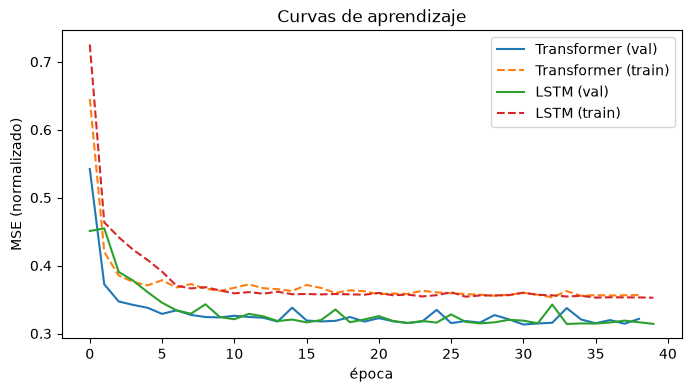

In [7]:
plt.figure(figsize=(8, 4))
for h, n_ in [(h_tf, "Transformer"), (h_lstm, "LSTM")]:
    plt.plot(h["val"], label=f"{n_} (val)"); plt.plot(h["train"], "--", label=f"{n_} (train)")
plt.xlabel("época"); plt.ylabel("MSE (normalizado)"); plt.legend(); plt.title("Curvas de aprendizaje"); plt.show()

## 5. Evaluación en el conjunto de prueba (en °C)

                MAE   RMSE
Persistencia  2.036  2.572
LSTM          1.716  2.201
Transformer   1.711  2.215

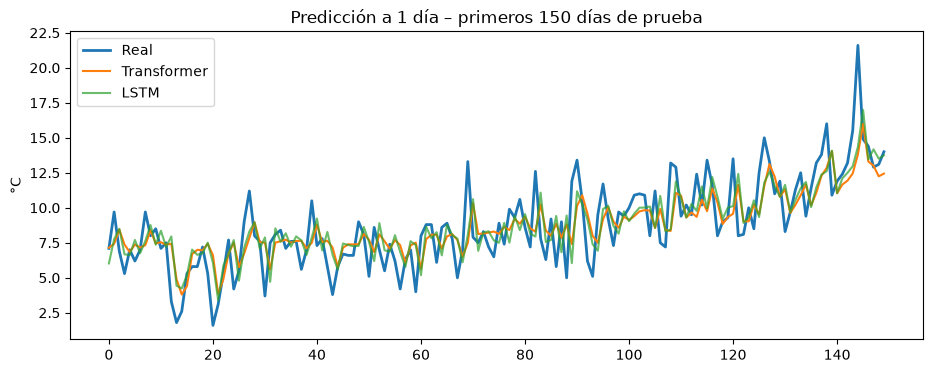

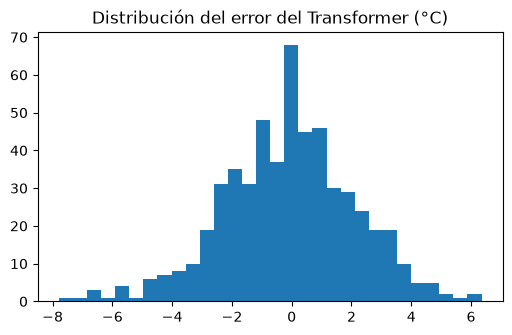

Error medio (sesgo): -0.083 °C | desv. típica: 2.214 °C


In [8]:
res = {"Persistencia": base}
m1, p_lstm, r = evaluar(m_lstm, Xte, yte); res["LSTM"] = m1
m2, p_tf, r = evaluar(m_tf, Xte, yte);     res["Transformer"] = m2
print(pd.DataFrame(res).T.round(3))

plt.figure(figsize=(11, 4)); k = slice(0, 150)
plt.plot(r[k], label="Real", lw=2); plt.plot(p_tf[k], label="Transformer"); plt.plot(p_lstm[k], label="LSTM", alpha=.7)
plt.title("Predicción a 1 día – primeros 150 días de prueba"); plt.ylabel("°C"); plt.legend(); plt.show()

err = p_tf - r
plt.figure(figsize=(6,3.5)); plt.hist(err, bins=30); plt.title("Distribución del error del Transformer (°C)"); plt.show()
print("Error medio (sesgo): %.3f °C | desv. típica: %.3f °C" % (err.mean(), err.std()))

## 6. Análisis de la autoatención
Mapa de atención de la **última capa** para una muestra de prueba, y atención promedio que recibe cada día desde el último paso de la ventana.

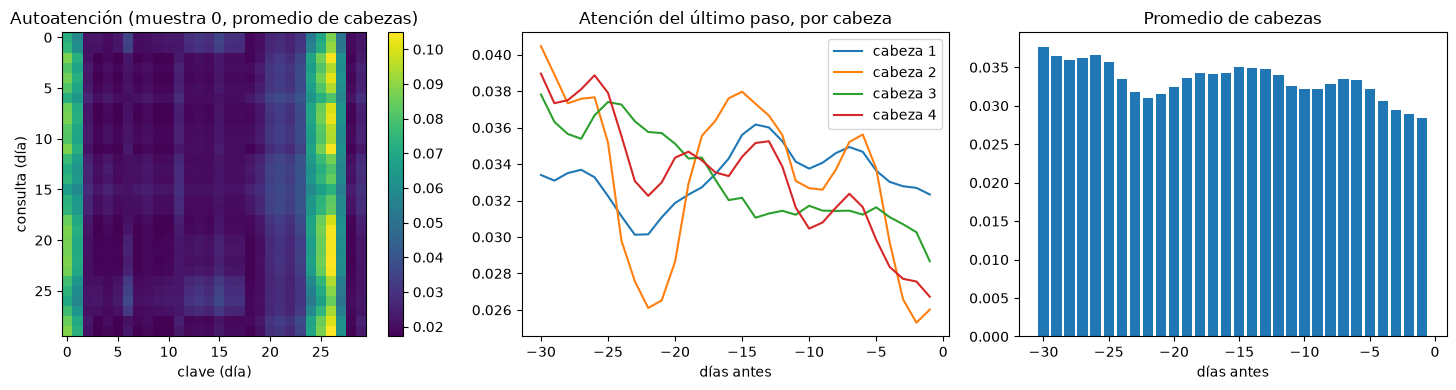

Peso medio de los últimos 3 días: 0.08682963997125626


In [9]:
m_tf.eval()
with torch.no_grad():
    _, mapas = m_tf(Xte[:200].to(device), return_att=True)
A = mapas[-1].cpu()                              # (B, h, L, L)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
im = ax[0].imshow(A[0].mean(0), cmap="viridis"); ax[0].set_title("Autoatención (muestra 0, promedio de cabezas)")
ax[0].set_xlabel("clave (día)"); ax[0].set_ylabel("consulta (día)"); plt.colorbar(im, ax=ax[0])
ult = A[:, :, -1, :].mean(0)                     # (h, L): atención desde el último paso
for i in range(ult.shape[0]): ax[1].plot(range(-VENTANA, 0), ult[i], label=f"cabeza {i+1}")
ax[1].set_title("Atención del último paso, por cabeza"); ax[1].set_xlabel("días antes"); ax[1].legend()
ax[2].bar(range(-VENTANA, 0), ult.mean(0)); ax[2].set_title("Promedio de cabezas"); ax[2].set_xlabel("días antes")
plt.tight_layout(); plt.show()
print("Peso medio de los últimos 3 días:", ult.mean(0)[-3:].sum().item())

## 7. Conclusiones del notebook
* Se construyó un Transformer Encoder funcional con atención multi-cabeza, codificación posicional, residuales y normalización de capa.
* Compare en la sección 5 su desempeño frente al LSTM y a la persistencia.
* Los mapas muestran que cada cabeza puede especializarse en distintos días de la ventana.

**Referencia:** Vaswani, A., et al. (2017). *Attention is all you need.* NeurIPS.